# prePilot Mouse trajectory recording audit

This notebook checks whether the optional eight movement module records interpretable paths. It loads canonical raw sessions directly, so a cumulative checkpoint and the final export are one run. Historical sessions without the module remain in the assignment inventory. An explicit clean folder can be inspected separately.

The analysis unit is a **session**. Eight movements from one participant are repeated observations, not eight participants. Repeated sessions from the same recorded participant identity are counted separately and identified in the audit. Synthetic paths are measurement controls, not labelled bots. These results do not validate a classifier or a participant exclusion rule.

| Section | Question |
| --- | --- |
| Input and completeness | Which runs requested the module and which recordings are complete? |
| Recorded paths | Do the paths reach the designed targets and contain excursions? |
| Sampling and geometry | Is timing consistent and is designed movement distance visible? |
| Matched controls | What changes when path shape or velocity profile is synthetic? |
| Operating checks | Which technical checks pass, fail or cannot be evaluated? |

Only public session labels appear in saved notebook outputs and figures. Private identifiers remain in local derived audit tables.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'static/task/mouse_qc').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook within the DroneTask repository.')
for folder in [ROOT / 'analysis', ROOT / 'analysis/mouse_qc']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from session_io import load_module_tables
from mouse_features import (GEOMETRY_G1, CORE_FEATURES, movement_table,
    trajectory_points, features_from_table, summarise_by_participant,
    build_matched_synthetic_set, descriptive_spearman, rank_auc)

CLEAN_OVERRIDE = os.environ.get('DRONE_CLEAN_DIR')
INPUT_MODE = os.environ.get('DRONE_INPUT_MODE', 'clean' if CLEAN_OVERRIDE else 'raw')
DERIVED = Path(os.environ.get('DRONE_DERIVED_DIR', ROOT / 'analysis/data/prePilot/mouse_qc/derived')).expanduser().resolve()
FIGURES = DERIVED / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261026)
CRITERIA = dict(min_complete_rate=.90, min_sampling_pass_rate=.80,
    min_points_median=20, max_dt_median_ms=20., min_geometry_rho=.50,
    max_efficiency_median=.99, min_type_a_separation=.80, max_abs_turn_dt_rho=.50)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 170,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.labelsize': 10, 'font.size': 10})
COLORS = ['#2563eb', '#db2777', '#16a34a', '#d97706', '#7c3aed', '#0891b2', '#64748b', '#dc2626']

def save_figure(fig, stem):
    fig.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

def column(df, name, default=pd.NA):
    return df[name] if name in df else pd.Series(default, index=df.index)

def truth(value):
    if value is None or value is pd.NA or pd.isna(value):
        return None
    text = str(value).strip().lower()
    if text in {'true', '1', '1.0', 'yes', 'on', 't'}: return True
    if text in {'false', '0', '0.0', 'no', 'off', 'f'}: return False
    return None

def number(value):
    return pd.to_numeric(pd.Series([value]), errors='coerce').iloc[0]

loaded = load_module_tables('mouse_qc', root=ROOT, input_mode=INPUT_MODE, clean_dir=CLEAN_OVERRIDE if INPUT_MODE == 'clean' else None)
traj = loaded['tables'].get('mouse_trajectory', pd.DataFrame()).copy()
summ = loaded['tables'].get('mouse_summary', pd.DataFrame()).copy()
meta = loaded['tables'].get('metadata', pd.DataFrame()).copy()
inventory, input_issues = loaded['inventory'], loaded['issues']
MOVEMENTS = movement_table()
print(f'Input mode {INPUT_MODE}. Canonical runs {len(inventory)}. Mouse trajectory rows {len(traj)}. Summary rows {len(summ)}.')
if len(input_issues):
    # Issue details can include private source paths, so retain those only in the local audit CSV.
    safe_cols = [k for k in ['session_label', 'severity', 'check', 'code', 'issue_type'] if k in input_issues]
    if safe_cols: display(input_issues[safe_cols])
    else: print(f'Input issues requiring review {len(input_issues)}. See private derived input issue table.')

Input mode raw. Canonical runs 3. Mouse trajectory rows 8. Summary rows 1.


## Session inventory

A requested or enabled module, or a mouse QC task variant, defines the expected completion denominator. Missing assignment fields remain **unknown** rather than being counted as unassigned or failed. A summary alone demonstrates an observed module, but does not reconstruct a missing assignment.

A complete feature session needs one terminal summary with status `complete` or `completed`, exactly one completed movement for every integer ID 1 through 8, a summary count of 8 when supplied, and the supported target geometry. Repeated movement IDs cannot conceal a missing movement. Raw malformed arrays, timestamp reversals and truncation are also audited. Off square coordinates are retained and flagged rather than clipped or silently excluded.

In [2]:
# Build one audit row per canonical run, including sessions with no mouse rows.
frames = [d for d in [meta, summ, traj, inventory] if len(d) and 'session_id' in d]
ids = sorted(set().union(*(set(d.session_id.dropna()) for d in frames))) if frames else []
rows = []
for sid in ids:
    m = meta[meta.session_id.eq(sid)] if len(meta) else pd.DataFrame()
    s = summ[summ.session_id.eq(sid)] if len(summ) else pd.DataFrame()
    t = traj[traj.session_id.eq(sid)] if len(traj) else pd.DataFrame()
    inv = inventory[inventory.session_id.eq(sid)] if len(inventory) and 'session_id' in inventory else pd.DataFrame()
    sources = [f.iloc[-1] for f in [m, s, t, inv] if len(f)]
    def pick(key, default=pd.NA):
        return next((r[key] for r in sources if key in r and pd.notna(r[key])), default)
    requested = truth(pick('mouse_qc_requested'))
    enabled = truth(pick('mouse_qc_enabled'))
    variant = str(pick('task_variant', '')).lower().replace('_', '-')
    expected = requested is True or enabled is True or 'mouse-qc' in variant
    assignment = 'requested' if expected else ('not_requested' if requested is False or enabled is False else 'unknown')
    status = str(s.iloc[-1].get('mt_status', '')).strip().lower() if len(s) else 'missing_summary'
    completed = column(t, 'trajectory_completed').map(truth).eq(True)
    parsed = pd.to_numeric(column(t, 'trajectory_id'), errors='coerce')
    valid_ids = parsed.notna() & parsed.mod(1).eq(0)
    tids = parsed[completed & valid_ids].astype(int).tolist()
    counts = pd.Series(tids, dtype='int64').value_counts()
    exact_ids = (len(t) == 8 and completed.all() and valid_ids.all() and set(tids) == set(range(1, 9)) and counts.eq(1).all())
    count = number(s.iloc[-1].get('mt_n_trajectories_completed')) if len(s) else np.nan
    count_ok = pd.isna(count) or count == 8
    geometry_ok, geometry_state = False, 'not_reported'
    if len(s) and pd.notna(s.iloc[-1].get('mt_geometry_json')):
        try:
            g = json.loads(s.iloc[-1].mt_geometry_json)
            geometry_ok = all(g.get(k) == GEOMETRY_G1[k] for k in ['start', 'targets', 'target_radius_frac', 'start_radius_frac'])
            geometry_state = 'supported' if geometry_ok else 'different_geometry'
        except (ValueError, TypeError): geometry_ok, geometry_state = False, 'invalid_geometry_json'
    complete = len(s) == 1 and status in {'complete', 'completed'}
    primary = bool(complete and exact_ids and count_ok and geometry_ok)
    reasons = []
    if len(s) != 1: reasons.append('missing_or_duplicate_summary')
    elif not complete: reasons.append('summary_not_complete')
    if len(t) and not exact_ids: reasons.append('movement_ids_or_completion_invalid')
    if not len(t) and (expected or len(s)): reasons.append('no_movement_rows')
    if not count_ok: reasons.append('summary_count_not_eight')
    if not geometry_ok and (expected or len(s) or len(t)): reasons.append(geometry_state)
    if not (expected or len(s) or len(t)):
        reasons = ['module_not_observed_assignment_unknown' if assignment == 'unknown' else 'module_not_requested']
    rows.append(dict(session_id=sid, session_label=pick('session_label', 'Unlabelled session'),
        participant_id=pick('participant_id'), source_schema=pick('source_schema'), task_version=pick('task_version'),
        qc_assignment=assignment, qc_expected=expected, trajectory_rows=len(t), summary_rows=len(s),
        mt_status=status, summary_completed=complete, completed_ids_exact=bool(exact_ids),
        missing_ids=','.join(map(str, sorted(set(range(1,9)) - set(tids)))) if (expected or len(s) or len(t)) else '',
        duplicate_ids=','.join(map(str, sorted(counts[counts.gt(1)].index))),
        invalid_id_rows=int((~valid_ids).sum()), summary_count_ok=bool(count_ok),
        geometry=geometry_state, primary_session=primary, audit_reason='; '.join(reasons),
        device=pick('mt_pointer_type_self_report'), resized=truth(pick('mt_resized_during_task')),
        summary_any_truncated=truth(pick('mt_any_truncated'))))
audit = pd.DataFrame(rows)
if audit.empty:
    audit = pd.DataFrame(columns=['session_id','session_label','participant_id','source_schema','task_version',
        'qc_assignment','qc_expected','primary_session','summary_completed','trajectory_rows','summary_rows','mt_status','audit_reason'])
# Distinct identities are counted separately from runs. Never print the private identity.
known_ids = audit.participant_id.astype('string').str.strip().replace('', pd.NA)
audit['identity_recorded'] = known_ids.notna()
audit['sessions_for_recorded_identity'] = known_ids.map(known_ids.value_counts()).astype('Int64')
primary_ids = set(audit.loc[audit.primary_session.eq(True), 'session_id'])
primary_traj = traj[traj.session_id.isin(primary_ids)].copy() if len(traj) else traj.copy()
excluded_traj = traj[~traj.session_id.isin(primary_ids)].copy() if len(traj) else traj.copy()
if len(primary_traj):
    primary_traj['trajectory_id'] = pd.to_numeric(primary_traj.trajectory_id).astype(int)
    # Nominal distances come directly from the acquisition geometry rather than the recorded click scatter.
    for k in ['nominal_length', 'movement_orientation', 'movement_length_class']:
        primary_traj[k] = primary_traj.trajectory_id.map(MOVEMENTS.set_index('trajectory_id')[k])
primary_people = known_ids[audit.primary_session.eq(True)]
N_SESSIONS = len(primary_ids)
N_KNOWN_PEOPLE = primary_people.nunique()
N_UNKNOWN_IDENTITIES = int(primary_people.isna().sum())
print(f'Complete QC sessions {N_SESSIONS}. Recorded distinct participant identities {N_KNOWN_PEOPLE}. Complete sessions without identity {N_UNKNOWN_IDENTITIES}.')
display(audit[[k for k in ['session_label','source_schema','task_version','qc_assignment',
    'trajectory_rows','summary_rows','mt_status','primary_session','device','audit_reason',
    'sessions_for_recorded_identity'] if k in audit]])
print('Assignment counts', audit.qc_assignment.value_counts().to_dict())
HAS_PRIMARY = bool(len(primary_traj))

Complete QC sessions 1. Recorded distinct participant identities 1. Complete sessions without identity 0.


,session_label,source_schema,task_version,qc_assignment,trajectory_rows,summary_rows,mt_status,primary_session,device,audit_reason,sessions_for_recorded_identity
0,Session 003,current,v3.14.0-acknowledged-data-saving,requested,8,1,complete,True,Mouse,,1
1,Session 002,legacy,v3.1-png-main-practice-emoji-latin-square-bloc...,unknown,0,0,missing_summary,False,NaN,module_not_observed_assignment_unknown,1
2,Session 001,legacy,v3.1-png-main-practice-emoji-latin-square-bloc...,unknown,0,0,missing_summary,False,NaN,module_not_observed_assignment_unknown,1


Assignment counts {'unknown': 2, 'requested': 1}


## Reconstruct and audit timing

Features use the opening click, every stored move and the closing click. Only consecutive points identical in both timestamp and position are removed. Timestamp ties remain, so speed uses positive time intervals only. No smoothing, spatial clipping or resampling is applied.

Duration includes waiting and corrective action between the two clicks. It is **not pure motor travel time**. Raw move cadence is reported separately from the cadence including click endpoints. Coalesced share is read from the raw array rather than inferred from a device label. A complete but unusual movement remains visible and can be inspected with an explicitly labelled sensitivity view.

In [3]:
id_cols = ('session_id', 'session_label', 'participant_id', 'trajectory_id')
feat_all = features_from_table(primary_traj, id_cols=id_cols)
if HAS_PRIMARY:
    feat_all['samples_truncated_bool'] = column(feat_all, 'samples_truncated').map(truth).eq(True)
    feat_all['sample_count_gap'] = pd.to_numeric(column(feat_all, 'n_samples'), errors='coerce') - feat_all.raw_move_samples
    feat_all['coalesced_count_gap'] = pd.to_numeric(column(feat_all, 'n_coalesced_samples'), errors='coerce') - feat_all.raw_coalesced_samples
    feat_all['signal_valid'] = (feat_all.parse_error.eq('') & feat_all.n_opening_clicks.eq(1) &
        feat_all.n_closing_clicks.eq(1) & feat_all.move_negative_dt_count.eq(0) &
        ~feat_all.samples_truncated_bool & feat_all.duration_ms.gt(0) &
        feat_all.duration_gap_ms.fillna(0).le(.2) & feat_all.sample_count_gap.fillna(0).eq(0) & feat_all.coalesced_count_gap.fillna(0).eq(0) &
        feat_all.samples_outside_click_window.eq(0))
    feat_all['audit_flag'] = np.select([~feat_all.signal_valid, feat_all.n_off_square_points.gt(0)],
        ['signal_requires_review', 'off_square_excursion'], default='none')
    feat = feat_all[feat_all.signal_valid].copy()
else:
    feat = feat_all.copy()
HAS_FEATURES = bool(len(feat))
if HAS_PRIMARY:
    display(feat_all[[k for k in ['session_label','trajectory_id','raw_move_samples','n_points',
        'median_dt_ms','move_median_positive_dt_ms','frac_zero_dt','coalesced_share',
        'duration_ms','duration_gap_ms','sample_count_gap','coalesced_count_gap','n_off_square_points','audit_flag'] if k in feat_all]].round(3))
    print(f'Usable recorded movements {len(feat)} of {len(feat_all)}. No flagged path is silently removed for looking unusual.')
if not HAS_FEATURES:
    print('No feature ready movements. Figures are skipped and operating checks remain not evaluable.')
# Check module totals against independently reconstructed row arrays and events.
summary_checks=[]
for _, summary in summ.iterrows():
    f=feat_all[feat_all.session_id.eq(summary.session_id)] if 'session_id' in feat_all else pd.DataFrame()
    for field,feature in [('mt_total_samples','raw_move_samples'),('mt_total_misclicks','n_misclick_events')]:
        expected=number(summary.get(field))
        observed=f[feature].sum(min_count=1) if len(f) else np.nan
        valid=np.isfinite(expected) and np.isfinite(observed) and len(f)==8 and f.parse_error.eq('').all()
        summary_checks.append(dict(session_id=summary.session_id,session_label=summary.session_label,
            check=field,recorded=expected,reconstructed=observed,
            status='not_evaluable' if not valid else ('pass' if expected==observed else 'fail')))
summary_checks=pd.DataFrame(summary_checks,columns=['session_id','session_label','check','recorded','reconstructed','status'])
if len(summary_checks): display(summary_checks.drop(columns='session_id'))


,session_label,trajectory_id,raw_move_samples,n_points,median_dt_ms,move_median_positive_dt_ms,frac_zero_dt,coalesced_share,duration_ms,duration_gap_ms,sample_count_gap,coalesced_count_gap,n_off_square_points,audit_flag
0,Session 003,1,342,344,8.40,8.40,0.0,1.0,10806.1,0.0,0.0,0.0,46,off_square_excursion
1,Session 003,2,27,29,8.10,8.05,0.0,1.0,880.7,0.0,0.0,0.0,0,none
2,Session 003,3,26,28,8.00,7.80,0.0,1.0,698.1,0.0,0.0,0.0,0,none
3,Session 003,4,57,59,8.25,8.20,0.0,1.0,774.5,0.0,0.0,0.0,0,none
4,Session 003,5,48,50,8.10,8.10,0.0,1.0,776.7,0.0,0.0,0.0,0,none
5,Session 003,6,66,68,8.20,8.10,0.0,1.0,846.3,0.0,0.0,0.0,0,none
6,Session 003,7,47,49,8.05,8.00,0.0,1.0,718.2,0.0,0.0,0.0,0,none
7,Session 003,8,65,67,8.40,8.35,0.0,1.0,1100.1,0.0,0.0,0.0,0,none


Usable recorded movements 8 of 8. No flagged path is silently removed for looking unusual.


,session_label,check,recorded,reconstructed,status
0,Session 003,mt_total_samples,678.0,678,pass
1,Session 003,mt_total_misclicks,1.0,1,pass


## Recorded paths

Each panel is one movement, with the nominal target centres and an unsmoothed observed path. Dotted segments connect nominal centres. Open circles mark target areas, the filled circle marks the recorded opening click and the square marks the recorded closing click. Axes include **all recorded coordinates**, including positions outside the unit square. Multiple sessions use distinct colours.

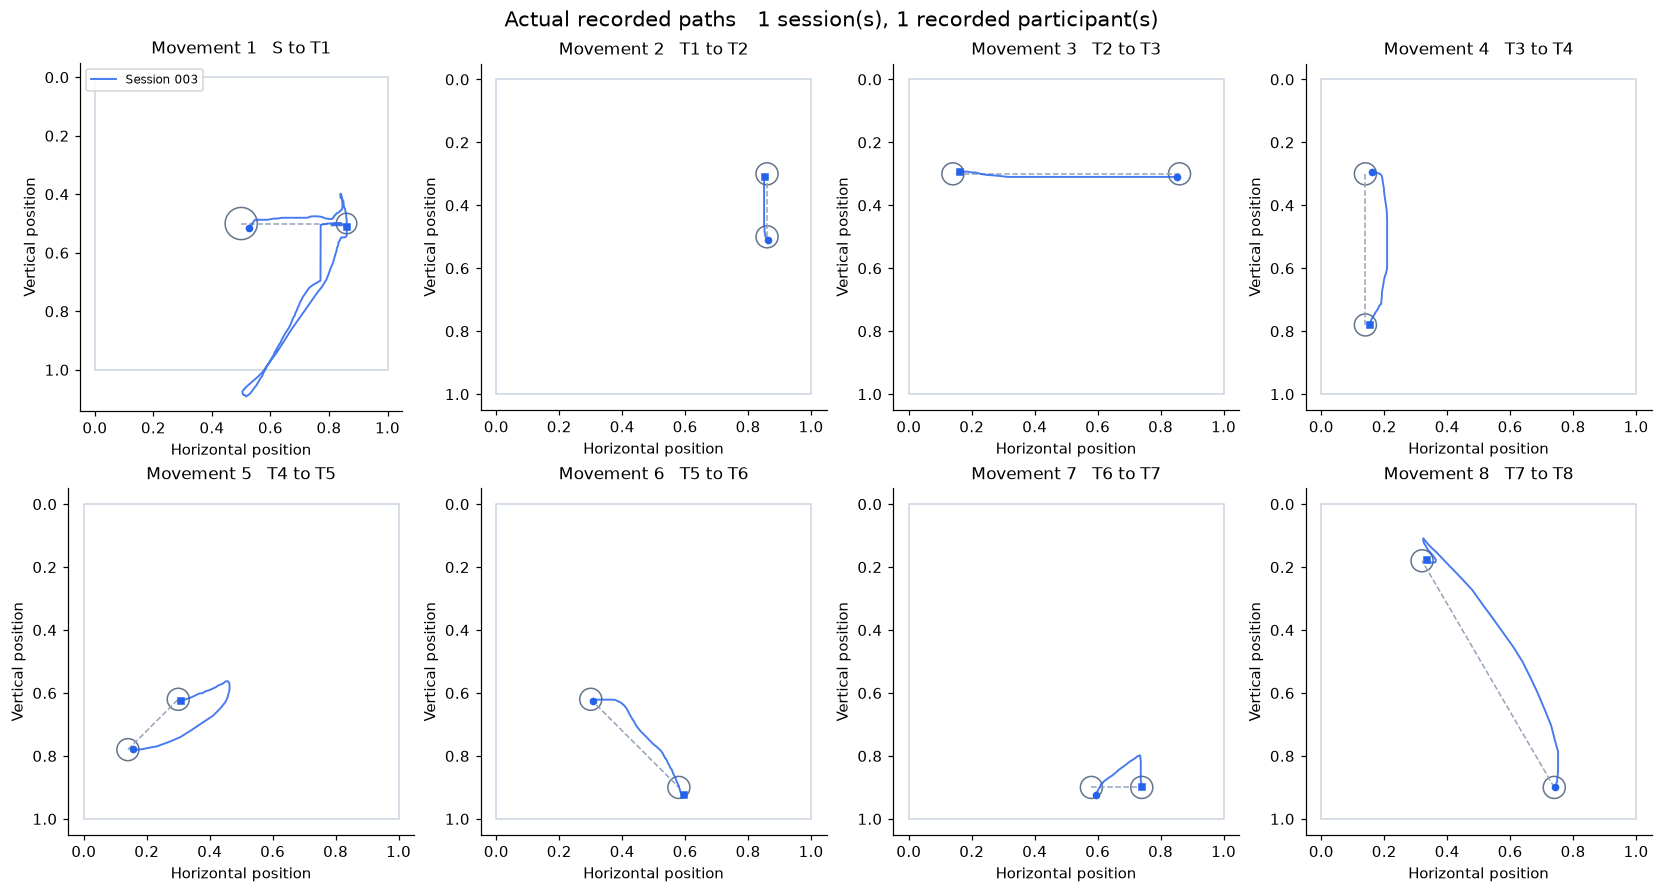

In [4]:
if HAS_FEATURES:
    fig, axes = plt.subplots(2, 4, figsize=(15, 8), layout='constrained')
    session_colors = {sid: COLORS[i % len(COLORS)] for i, sid in enumerate(sorted(feat.session_id.unique()))}
    for tid, ax in enumerate(axes.flat, 1):
        m = MOVEMENTS.set_index('trajectory_id').loc[tid]
        ax.add_patch(plt.Rectangle((0,0),1,1, fill=False, ec='#cbd5e1', lw=1))
        ax.plot([m.x0,m.x1],[m.y0,m.y1], '--', color='#94a3b8', lw=1)
        for j,(xx, yy) in enumerate([(m.x0,m.y0),(m.x1,m.y1)]):
            radius = GEOMETRY_G1['start_radius_frac'] if tid == 1 and j == 0 else GEOMETRY_G1['target_radius_frac']
            ax.add_patch(plt.Circle((xx,yy), radius, fill=False, ec='#64748b'))
        all_x, all_y = [0,1], [0,1]
        valid_keys = set(zip(feat.session_id, feat.trajectory_id))
        for _, row in primary_traj[primary_traj.trajectory_id.eq(tid)].iterrows():
            if (row.session_id,tid) not in valid_keys: continue
            t,x,y = trajectory_points(row.samples,row.events)
            ax.plot(x,y,lw=1.25,alpha=.85,color=session_colors[row.session_id],label=row.session_label)
            ax.plot(x[0],y[0],'o',color=session_colors[row.session_id],ms=4)
            ax.plot(x[-1],y[-1],'s',color=session_colors[row.session_id],ms=4)
            all_x.extend(x); all_y.extend(y)
        ax.set_xlim(min(all_x)-.05,max(all_x)+.05)
        ax.set_ylim(max(all_y)+.05,min(all_y)-.05)
        ax.set_aspect('equal',adjustable='box')
        ax.set_title(f'Movement {tid}   {m["from"]} to {m["to"]}')
        ax.set_xlabel('Horizontal position'); ax.set_ylabel('Vertical position')
        if tid == 1: ax.legend(fontsize=8,loc='upper left')
    fig.suptitle(f'Actual recorded paths   {N_SESSIONS} session(s), {N_KNOWN_PEOPLE} recorded participant(s)', fontsize=14)
    save_figure(fig,'mouse_recorded_paths')

## Sampling and movement geometry

Point counts and sampling intervals are shown per movement rather than as a population distribution. The duration panel exposes waiting or excursions. The geometry panel checks whether longer designed movements produce longer paths. Labels identify movement IDs. A single recording cannot estimate browser or device differences.

The optional view omitting paths with off square coordinates is a **descriptive sensitivity check**, not a quality based exclusion. Both views are retained. Correlations have no population p values because movements within one person are not independent participants.

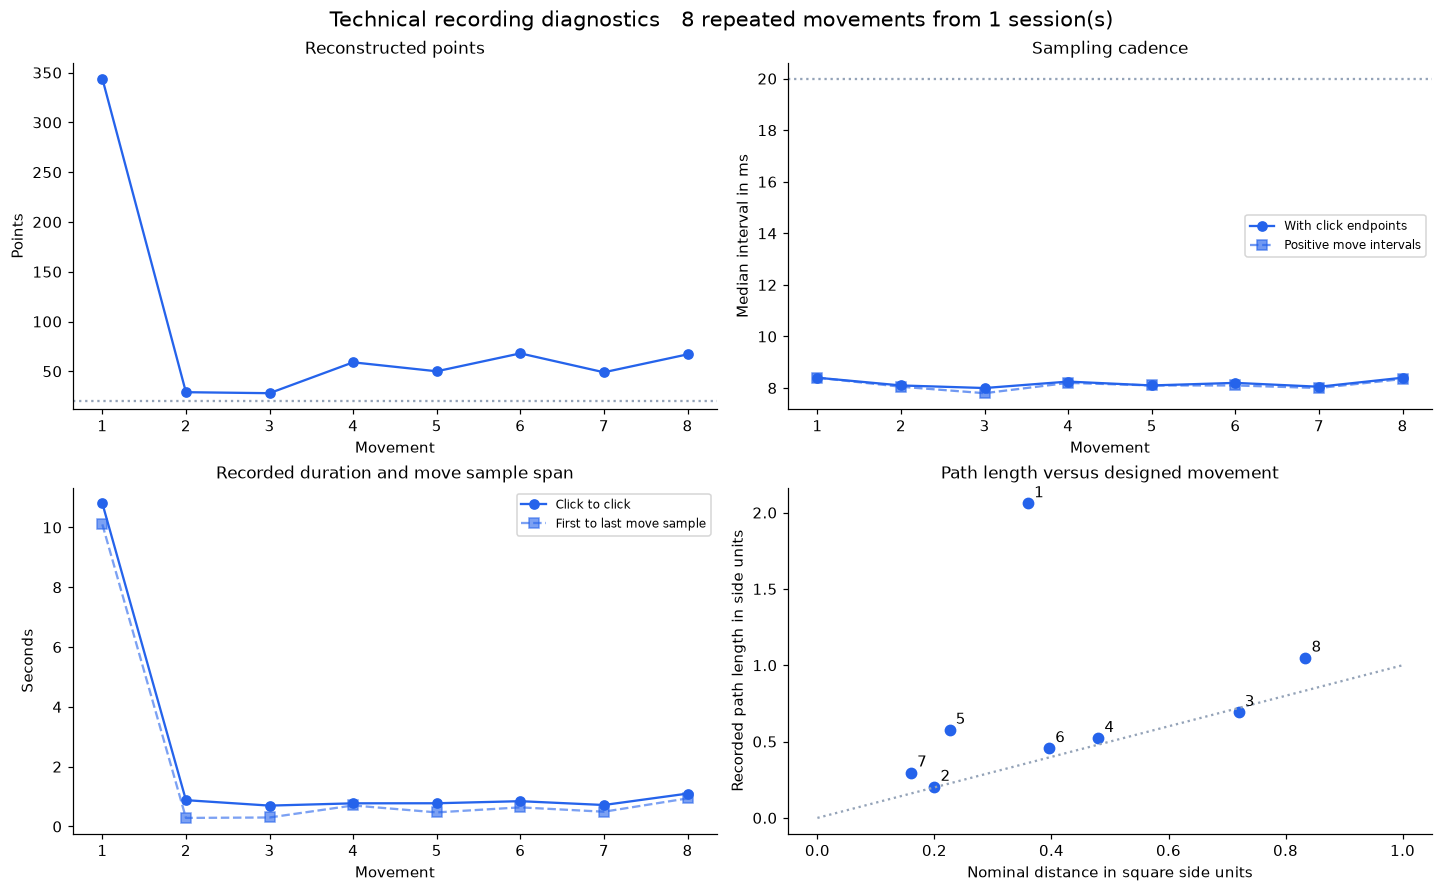

,session_label,n_trajectories,duration_ms_median,path_length_median,efficiency_median,mean_abs_turn_deg_median,n_points_median,median_dt_ms_median
0,Session 003,8,811.5,0.55,0.848,12.678,54.5,8.15


,view,movements,rho,status,median_efficiency,reason
0,All usable movements,8,0.619,evaluated,0.848,
1,Without off square paths,7,0.857,evaluated,0.907,


In [5]:
if HAS_FEATURES:
    fig, axes = plt.subplots(2,2,figsize=(13,8),layout='constrained')
    for sid, group in feat.groupby('session_id'):
        g = group.sort_values('trajectory_id'); color=session_colors[sid]
        axes[0,0].plot(g.trajectory_id,g.n_points,'o-',color=color,label=g.session_label.iloc[0])
        axes[0,1].plot(g.trajectory_id,g.median_dt_ms,'o-',color=color,label='With click endpoints')
        axes[0,1].plot(g.trajectory_id,g.move_median_positive_dt_ms,'s--',color=color,alpha=.65,label='Positive move intervals')
        axes[1,0].plot(g.trajectory_id,g.duration_ms/1000,'o-',color=color,label='Click to click')
        axes[1,0].plot(g.trajectory_id,g.raw_move_span_ms/1000,'s--',color=color,alpha=.6,label='First to last move sample')
        axes[1,1].scatter(g.nominal_length,g.path_length,s=45,color=color)
        for _, r in g.iterrows(): axes[1,1].annotate(str(int(r.trajectory_id)),(r.nominal_length,r.path_length),xytext=(4,4),textcoords='offset points')
    axes[0,0].axhline(CRITERIA['min_points_median'],color='#94a3b8',ls=':')
    axes[0,0].set(title='Reconstructed points',ylabel='Points',xlabel='Movement')
    axes[0,1].axhline(CRITERIA['max_dt_median_ms'],color='#94a3b8',ls=':')
    axes[0,1].set(title='Sampling cadence',ylabel='Median interval in ms',xlabel='Movement')
    axes[1,0].set(title='Recorded duration and move sample span',ylabel='Seconds',xlabel='Movement')
    axes[1,1].plot([0,1],[0,1],':',color='#94a3b8',label='Path equals nominal distance')
    axes[1,1].set(title='Path length versus designed movement',xlabel='Nominal distance in square side units',ylabel='Recorded path length in side units')
    for ax in [axes[0,0],axes[0,1],axes[1,0]]: ax.set_xticks(range(1,9))
    for ax in [axes[0,1],axes[1,0]]:
        h,l=ax.get_legend_handles_labels(); unique=dict(zip(l,h)); ax.legend(unique.values(),unique.keys(),fontsize=8)
    fig.suptitle(f'Technical recording diagnostics   {len(feat)} repeated movements from {N_SESSIONS} session(s)',fontsize=14)
    save_figure(fig,'mouse_sampling_geometry')

    session_summary = summarise_by_participant(feat, CORE_FEATURES + ['n_points','median_dt_ms'],unit_col='session_id')
    session_summary = session_summary.merge(audit[['session_id','session_label']],on='session_id',how='left')
    display(session_summary[['session_label','n_trajectories','duration_ms_median',
        'path_length_median','efficiency_median','mean_abs_turn_deg_median',
        'n_points_median','median_dt_ms_median']].round(3))
    geometry_views=[]
    for label, f in [('All usable movements',feat),('Without off square paths',feat[feat.n_off_square_points.eq(0)])]:
        corr=descriptive_spearman(f.nominal_length,f.path_length)
        geometry_views.append(dict(view=label,movements=len(f),rho=corr['rho'],status=corr['status'],
            median_efficiency=f.efficiency.median(),reason=corr['reason']))
    geometry_sensitivity=pd.DataFrame(geometry_views)
    display(geometry_sensitivity.round(3))
else:
    session_summary=pd.DataFrame(); geometry_sensitivity=pd.DataFrame()

## Controls matched to the recording

All three controls retain each actual click endpoint, timestamp, input sample count and duration. If different recorded positions share a timestamp, a deterministic synthetic path gives them the same position and its exact duplicates collapse during reconstruction. That difference is reported rather than hidden. Constant speed straight paths and minimum jerk straight paths are generated once per observed movement. Thirty curved minimum jerk paths per movement vary only curvature. Synthetic draws are **simulation replicates**, never additional participants. The same feature extractor is used for recorded and simulated arrays.

The controls test feature behaviour under simple geometric and velocity changes. Separation from a perfectly straight path is an easy measurement check. It cannot estimate real bot detection, effort, compliance or exclusion accuracy. The curved range is the range of generated simulations, not a confidence interval.

The timing example uses the recorded movement closest to the median click duration. Its projection along the start to end direction shows why the two straight controls differ in timing despite sharing efficiency and turning values. Curved controls use minimum jerk progress along a quadratic curve, rather than enforcing a minimum jerk tangential speed.

Matched controls 256 simulated paths. Exact input timestamp, endpoint and duration checks passed. Reconstructed point counts matched True.


,feature,control,rank_probability,separation
0,efficiency,A_linear_const,0.000,1.000
1,efficiency,B_linear_accdec,0.000,1.000
2,efficiency,C_curved_accdec,0.196,0.607
3,mean_abs_turn_deg,A_linear_const,1.000,1.000
4,mean_abs_turn_deg,B_linear_accdec,1.000,1.000
5,mean_abs_turn_deg,C_curved_accdec,1.000,1.000


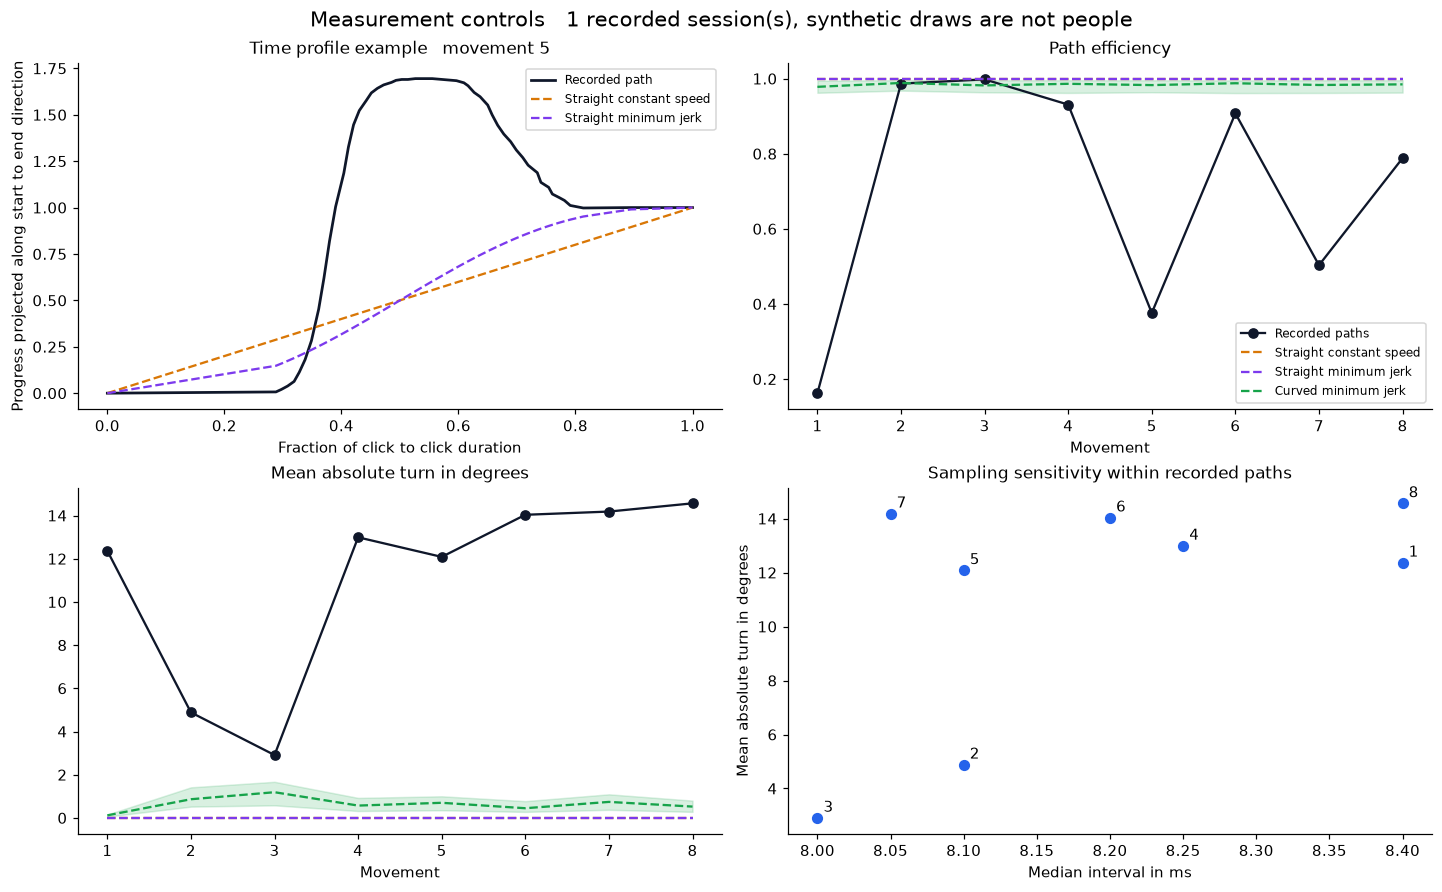

In [6]:
if HAS_FEATURES:
    good_keys=set(zip(feat.session_id,feat.trajectory_id))
    matched_input=primary_traj[[ (r.session_id,r.trajectory_id) in good_keys for _,r in primary_traj.iterrows() ]]
    synthetic=build_matched_synthetic_set(matched_input,RNG,n_curved=30)
    sf=features_from_table(synthetic,id_cols=('session_id','session_label','trajectory_id','source','draw'))
    # Exact matching is checked in code, not assumed from the generator name.
    match=sf.merge(feat[['session_id','trajectory_id','duration_ms','n_points','displacement']],
        on=['session_id','trajectory_id'],suffixes=('_synthetic','_observed'))
    assert np.allclose(match.duration_ms_synthetic,match.duration_ms_observed)
    count_matched = match.n_points_synthetic.eq(match.n_points_observed).all()
    if not count_matched:
        print('Some control points collapse at tied timestamps. Input timestamp arrays are identical; reconstructed counts differ as documented.')
    assert np.allclose(match.displacement_synthetic,match.displacement_observed)
    for _, control in synthetic.iterrows():
        observed = matched_input[(matched_input.session_id.eq(control.session_id)) & (matched_input.trajectory_id.eq(control.trajectory_id))].iloc[0]
        observed_t = trajectory_points(observed.samples, observed.events)[0]
        control_t = np.array([json.loads(control.events)[0][0]] + [s[0] for s in json.loads(control.samples)] + [json.loads(control.events)[-1][0]])
        assert np.array_equal(observed_t, control_t)
    print(f'Matched controls {len(synthetic)} simulated paths. Exact input timestamp, endpoint and duration checks passed. Reconstructed point counts matched {bool(count_matched)}.')
    separation=[]
    for feature in ['efficiency','mean_abs_turn_deg']:
        for source in ['A_linear_const','B_linear_accdec','C_curved_accdec']:
            auc=rank_auc(feat[feature],sf.loc[sf.source.eq(source),feature])
            separation.append(dict(feature=feature,control=source,rank_probability=auc,separation=2*abs(auc-.5)))
    separation=pd.DataFrame(separation)
    display(separation.round(3))

    # Timing profile adds information that the shape features intentionally omit.
    fig,axes=plt.subplots(2,2,figsize=(13,8),layout='constrained')
    median_duration=feat.duration_ms.median()
    representative_key=feat.loc[(feat.duration_ms-median_duration).abs().idxmin()]
    representative=matched_input[matched_input.session_id.eq(representative_key.session_id)&matched_input.trajectory_id.eq(representative_key.trajectory_id)].iloc[0]
    t,x,y=trajectory_points(representative.samples,representative.events)
    start=np.array([x[0],y[0]]); chord=np.array([x[-1],y[-1]])-start
    def projected_progress(xx,yy):
        return ((np.column_stack([xx,yy])-start)@chord)/np.dot(chord,chord)
    axes[0,0].plot((t-t[0])/(t[-1]-t[0]),projected_progress(x,y),color='#0f172a',lw=1.8,label='Recorded path')
    names={'A_linear_const':'Straight constant speed','B_linear_accdec':'Straight minimum jerk','C_curved_accdec':'Curved minimum jerk'}
    palette={'A_linear_const':'#d97706','B_linear_accdec':'#7c3aed','C_curved_accdec':'#16a34a'}
    one=synthetic[synthetic.session_id.eq(representative.session_id)&synthetic.trajectory_id.eq(representative.trajectory_id)&synthetic.draw.eq(0)]
    for _,r in one[~one.source.eq('C_curved_accdec')].iterrows():
        tt,xx,yy=trajectory_points(r.samples,r.events)
        axes[0,0].plot((tt-tt[0])/(tt[-1]-tt[0]),projected_progress(xx,yy),color=palette[r.source],ls='--',lw=1.5,label=names[r.source])
    axes[0,0].set(title=f'Time profile example   movement {int(representative.trajectory_id)}',xlabel='Fraction of click to click duration',ylabel='Progress projected along start to end direction')
    axes[0,0].legend(fontsize=8)
    for ax,feature,title in [(axes[0,1],'efficiency','Path efficiency'),(axes[1,0],'mean_abs_turn_deg','Mean absolute turn in degrees')]:
        for sid,g in feat.groupby('session_id'):
            ax.plot(g.trajectory_id,g[feature],'o-',color='#0f172a',label='Recorded paths' if sid==feat.session_id.iloc[0] else None)
        for source,g in sf.groupby('source'):
            agg=g.groupby('trajectory_id')[feature].agg(['median','min','max'])
            ax.plot(agg.index,agg['median'],ls='--',color=palette[source],label=names[source])
            if source.startswith('C_'): ax.fill_between(agg.index,agg['min'],agg['max'],color=palette[source],alpha=.16)
        ax.set(title=title,xlabel='Movement',xticks=range(1,9))
    # A logarithmic display would inflate numerical noise on straight controls. Keep degrees on the original scale.
    for _,r in feat.iterrows():
        axes[1,1].scatter(r.median_dt_ms,r.mean_abs_turn_deg,color=session_colors[r.session_id],s=40)
        axes[1,1].annotate(str(int(r.trajectory_id)),(r.median_dt_ms,r.mean_abs_turn_deg),xytext=(4,4),textcoords='offset points')
    axes[1,1].set(title='Sampling sensitivity within recorded paths',xlabel='Median interval in ms',ylabel='Mean absolute turn in degrees')
    axes[0,1].legend(fontsize=8)
    fig.suptitle(f'Measurement controls   {N_SESSIONS} recorded session(s), synthetic draws are not people',fontsize=14)
    save_figure(fig,'mouse_matched_controls')
else:
    synthetic=pd.DataFrame();sf=pd.DataFrame();separation=pd.DataFrame()

## Operating checks

These are proposed lab operating tolerances, not cutoffs validated by the cited mouse dynamics studies. A check can pass descriptively while population adequacy remains unknown. Missing or constant inputs produce **not_evaluable**, never pass. The sensitivity correlation is descriptive within recordings and can reflect target geometry as well as sampling. It does not estimate an independent effect of browser cadence.

The completeness denominator uses only known requested sessions. Unknown legacy assignments are reported separately. Sampling applies only to sessions with all eight signal valid movements. A recorded identity can have multiple sessions, so neither the number of sessions nor the number of movements should be presented as the number of independent people.

In [7]:
checks=[]
def add_check(name,value,criterion,passed=None,scope='Technical descriptive check'):
    checks.append(dict(check=name,value=value,criterion=criterion,
        status='not_evaluable' if passed is None else ('pass' if bool(passed) else 'fail'),scope=scope))
expected=audit[audit.qc_expected.eq(True)]
completion_rate=expected.summary_completed.mean() if len(expected) else np.nan
add_check('Module completion',f'{int(expected.summary_completed.sum())} of {len(expected)} known requested sessions',
    'At least 90 percent',None if not len(expected) else completion_rate>=CRITERIA['min_complete_rate'])
if HAS_FEATURES:
    usable_counts=feat.groupby('session_id').size()
    complete_signal_ids=set(usable_counts[usable_counts.eq(8)].index)
    sfloor=(feat[feat.session_id.isin(complete_signal_ids)].groupby('session_id')
        .agg(points_median=('n_points','median'),dt_median=('median_dt_ms','median')))
    sfloor['pass']=(sfloor.points_median.ge(CRITERIA['min_points_median']) & sfloor.dt_median.le(CRITERIA['max_dt_median_ms']))
    sampling_rate=sfloor['pass'].sum()/N_SESSIONS if N_SESSIONS else np.nan
    add_check('Sampling availability',f'{int(sfloor["pass"].sum())} of {N_SESSIONS} complete sessions meet sampling floor',
        'At least 80 percent with median points at least 20 and interval at most 20 ms',
        None if not N_SESSIONS else sampling_rate>=CRITERIA['min_sampling_pass_rate'])
    gc=descriptive_spearman(feat.nominal_length,feat.path_length)
    eff=feat.efficiency.median()
    add_check('Geometry sanity',f'Rank correlation {gc["rho"]:.3f}, median efficiency {eff:.3f}',
        'Correlation above 0.50 and median efficiency below 0.99',
        None if gc['status']!='evaluated' else gc['rho']>CRITERIA['min_geometry_rho'] and eff<CRITERIA['max_efficiency_median'])
    sep=separation.loc[separation.control.eq('A_linear_const'),'separation'].max()
    add_check('Straight control separation',f'{sep:.3f}', 'Efficiency or turning separation at least 0.80',
        None if not np.isfinite(sep) else sep>=CRITERIA['min_type_a_separation'],scope='Measurement sanity only')
    sensitivity=descriptive_spearman(feat.median_dt_ms,feat.mean_abs_turn_deg)
    add_check('Sampling sensitivity',f'Rank correlation {sensitivity["rho"]:.3f} across {sensitivity["n_pairs"]} movements',
        'Absolute correlation below 0.50',None if sensitivity['status']!='evaluated' else abs(sensitivity['rho'])<CRITERIA['max_abs_turn_dt_rho'],
        scope='Repeated movement diagnostic, not a device comparison')
else:
    sfloor=pd.DataFrame(); sensitivity=dict(status='not_evaluable',rho=np.nan,n_pairs=0,reason='no_usable_movements')
    for name in ['Sampling availability','Geometry sanity','Straight control separation','Sampling sensitivity']:
        add_check(name,'No usable complete recording','Collect usable recordings')
checks=pd.DataFrame(checks)
display(checks)
if N_KNOWN_PEOPLE < 2 or N_SESSIONS < 2:
    display(Markdown('**Interpretation**  This is a single session technical rehearsal. Eight movements cannot establish participant level variability, browser differences, false exclusions or classifier accuracy.'))
else:
    display(Markdown('**Interpretation**  These are descriptive recording checks. Population validation requires more independent participants and a separate design with appropriate labelled outcomes.'))
if len(audit) and audit.sessions_for_recorded_identity.fillna(0).gt(1).any():
    print('Repeated recorded identities are present. Use a participant level or hierarchical analysis before any population inference.')
print(f'Legacy or otherwise unknown module assignments {int(audit.qc_assignment.eq("unknown").sum())}. They are not silently counted as failures or successes.')

,check,value,criterion,status,scope
0,Module completion,1 of 1 known requested sessions,At least 90 percent,pass,Technical descriptive check
1,Sampling availability,1 of 1 complete sessions meet sampling floor,At least 80 percent with median points at leas...,pass,Technical descriptive check
2,Geometry sanity,"Rank correlation 0.619, median efficiency 0.848",Correlation above 0.50 and median efficiency b...,pass,Technical descriptive check
3,Straight control separation,1.000,Efficiency or turning separation at least 0.80,pass,Measurement sanity only
4,Sampling sensitivity,Rank correlation 0.443 across 8 movements,Absolute correlation below 0.50,pass,"Repeated movement diagnostic, not a device com..."


**Interpretation**  This is a single session technical rehearsal. Eight movements cannot establish participant level variability, browser differences, false exclusions or classifier accuracy.

Legacy or otherwise unknown module assignments 2. They are not silently counted as failures or successes.


## Exported audit products

PNG figures are also embedded above. Derived tables contain the session audit, every reconstructed movement and its signal flags, usable features, session summaries, synthetic checks and operating checks. Excluded incomplete sessions remain in an audit export. The source sample arrays remain in the original data rather than being duplicated into every feature table.

| Product | Location relative to the repository |
| --- | --- |
| Figures | `analysis/data/prePilot/mouse_qc/derived/figures` |
| Session inventory and flags | `analysis/data/prePilot/mouse_qc/derived/mouse_qc_session_audit.csv` |
| All reconstructed movement features | `analysis/data/prePilot/mouse_qc/derived/mouse_qc_all_movement_features.csv` |
| Usable movement features | `analysis/data/prePilot/mouse_qc/derived/mouse_qc_trajectory_features.csv` |
| One summary per session | `analysis/data/prePilot/mouse_qc/derived/mouse_qc_session_summary.csv` |
| Operating check results | `analysis/data/prePilot/mouse_qc/derived/mouse_qc_operating_checks.csv` |

Local identifiers are useful for joining private data, but these derived CSVs are gitignored and must be handled as research data. Notebook displays intentionally use public session labels. Full browser strings, raw filenames and demographic values are never printed.

In [8]:
exports={
    'mouse_qc_session_audit':audit,
    'mouse_qc_all_movement_features':feat_all,
    'mouse_qc_trajectory_features':feat,
    'mouse_qc_session_summary':session_summary,
    'mouse_qc_geometry_sensitivity':geometry_sensitivity,
    'mouse_qc_synthetic_separation':separation,
    'mouse_qc_operating_checks':checks,
    'mouse_qc_sampling_summary':sfloor.reset_index(),
    'mouse_qc_input_inventory':inventory,
    'mouse_qc_input_issues':input_issues,
    'mouse_qc_summary_consistency':summary_checks,
}
if len(excluded_traj):
    keep=[k for k in ['session_id','session_label','participant_id','trajectory_id',
        'trajectory_completed','samples_truncated'] if k in excluded_traj]
    exports['mouse_qc_excluded_trajectories']=excluded_traj[keep]
else:
    exports['mouse_qc_excluded_trajectories']=pd.DataFrame(columns=['session_id','session_label','trajectory_id'])
for stem,table in exports.items(): table.to_csv(DERIVED/f'{stem}.csv',index=False)
print(f'Exported {len(exports)} audit tables. Figures generated in this run {3 if HAS_FEATURES else 0}.')

Exported 12 audit tables. Figures generated in this run 3.


## Scope and references

The implementation records a fixed geometry and pointer samples, then derives simple global kinematics. The references motivate paradigm choice, synthetic controls and awareness of device and sampling effects. They do not validate the numerical lab tolerances or establish screening performance in this experiment. No paper specific feature set, trained classifier or diagnostic threshold is reproduced here.

| Source | Limited role in this analysis |
| --- | --- |
| [Shen and colleagues 2014](https://doi.org/10.1016/j.cose.2014.05.002) | Background for mouse dynamics acquisition and anomaly detection |
| [Acien and colleagues 2022](https://doi.org/10.1016/j.patcog.2022.108643) | Motivation for simple synthetic shape and velocity controls |
| [Fitts 1954](https://doi.org/10.1037/h0055392) | Rationale for inspecting the designed movement geometry, without claiming a fitted Fitts law model |
| [Kieslich and colleagues 2020](https://doi.org/10.3758/s13428-019-01228-y) | Design sensitivity of mouse tracking measurements |
| [Warburton and colleagues 2025](https://doi.org/10.1007/s00426-024-02065-1) | Motivation to retain device distinctions when an adequate sample becomes available |
| [Pointer Events Level 3](https://www.w3.org/TR/pointerevents3/#coalesced-events) | Acquisition semantics for stored coalesced pointer samples |

The notebook intentionally omits acceleration, jerk, resampling based classifiers and population p values. New devices, geometry versions or recording failures should first be examined through the input and signal audit. A suspicious looking path alone is not evidence of a bot or a valid reason to exclude a participant.